# CHƯƠNG 3: KIỂM ĐỊNH GIẢ THUYẾT THỐNG KÊ (HYPOTHESIS TESTING)
**Đồ án môn học:** Phân tích và Trực quan hóa Dữ liệu (Bike Sharing Dataset)  
**Thành viên thực hiện:** TV3 - Phụ trách Kiểm định Giả thuyết Thống kê  
**Khung lý thuyết đối sánh:** *100 Statistical Tests* (3rd Edition, 2006) - Gopal K. Kanji  
**Dữ liệu sử dụng:** `EDA/cleaned_data/hour_cleaned.csv` ($N = 17,379$ quan sát)

---

### Mục tiêu nghiên cứu:
Kiểm định giả thuyết nhằm đưa ra các bằng chứng thống kê khách quan, phân biệt rõ giữa "biến thiên ngẫu nhiên" và "sai biệt thực chất có ý nghĩa", trả lời 2 câu hỏi nghiệp vụ cốt lõi:
1. **Câu hỏi nghiên cứu 1 (RQ1):** *Có sự khác biệt có ý nghĩa thống kê về nhu cầu thuê xe trung bình mỗi giờ giữa Ngày làm việc (`workingday = 1`) và Ngày nghỉ/Cuối tuần (`workingday = 0`) hay không?*
2. **Câu hỏi nghiên cứu 2 (RQ2):** *Nhu cầu thuê xe trung bình có khác biệt giữa 4 mùa trong năm (`season`) hay không, và cụ thể những cặp mùa nào có sự sai biệt thực chất?*

### Quy trình kiểm định 5 bước Neave-Kanji (2006):
1. **Bước 1:** Phát biểu giả thuyết không ($H_0$) và giả thuyết đối ($H_1$).
2. **Bước 2:** Xác định mức ý nghĩa kiểm định $\alpha$ (mặc định $\alpha = 0.05$).
3. **Bước 3:** Lựa chọn đại lượng kiểm định (Test Statistic) phù hợp với bản chất dữ liệu (tham số / phi tham số).
4. **Bước 4:** Thu thập dữ liệu, kiểm tra giả định phân phối/phương sai và tính toán giá trị thống kê thực nghiệm kèm $p$-value.
5. **Bước 5:** Đưa ra kết luận thống kê (Bác bỏ $H_0$ hoặc Chưa đủ bằng chứng bác bỏ $H_0$) và phiên giải ý nghĩa nghiệp vụ kết hợp kích thước hiệu ứng (Effect Size).

## 1. Thiết lập môi trường và cấu hình đồ họa

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

# Cấu hình thư mục
DATA_PATH = os.path.join('..', 'EDA', 'cleaned_data', 'hour_cleaned.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('EDA', 'cleaned_data', 'hour_cleaned.csv')

ASSETS_DIR = 'assets'
os.makedirs(ASSETS_DIR, exist_ok=True)

# Thiết lập thẩm mỹ biểu đồ học thuật
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

print(f"Môi trường đã sẵn sàng. Dữ liệu: {DATA_PATH}")
print(f"Thư mục assets: {os.path.abspath(ASSETS_DIR)}")

Môi trường đã sẵn sàng. Dữ liệu: ..\EDA\cleaned_data\hour_cleaned.csv
Thư mục assets: D:\record_by_me\tdtu\Data_Analysis_and_Visualization\Finalterm\Hypothesis_Test\assets


## 2. Đọc và kiểm tra cấu trúc dữ liệu

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Kích thước tập dữ liệu: N = {len(df):,} dòng, {df.shape[1]} cột.")
print("\n5 dòng đầu tiên:")
df[['dteday', 'season', 'workingday', 'hr', 'temp', 'hum', 'windspeed', 'cnt']].head()

Kích thước tập dữ liệu: N = 17,379 dòng, 17 cột.

5 dòng đầu tiên:


,dteday,season,workingday,hr,temp,hum,windspeed,cnt
0,2011-01-01,1,0,0,0.24,0.81,0.0,16
1,2011-01-01,1,0,1,0.22,0.80,0.0,40
2,2011-01-01,1,0,2,0.22,0.80,0.0,32
3,2011-01-01,1,0,3,0.24,0.75,0.0,13
4,2011-01-01,1,0,4,0.24,0.75,0.0,1


## 3. Câu hỏi nghiên cứu 1 (RQ1): Ngày làm việc vs Ngày nghỉ
- **Giả thuyết $H_0$:** Không có sự khác biệt về nhu cầu thuê xe trung bình mỗi giờ giữa ngày làm việc và ngày nghỉ ($\mu_1 = \mu_0$).
- **Giả thuyết $H_1$:** Có sự khác biệt có ý nghĩa thống kê giữa ngày làm việc và ngày nghỉ ($\mu_1 \neq \mu_0$).
- Mức ý nghĩa: $\alpha = 0.05$.

In [3]:
g_work = df[df['workingday'] == 1]['cnt']
g_rest = df[df['workingday'] == 0]['cnt']

n_work, n_rest = len(g_work), len(g_rest)
mean_work, mean_rest = g_work.mean(), g_rest.mean()
med_work, med_rest = g_work.median(), g_rest.median()
std_work, std_rest = g_work.std(), g_rest.std()
skew_work, skew_rest = g_work.skew(), g_rest.skew()
kurt_work, kurt_rest = g_work.kurt(), g_rest.kurt()

rq1_desc = pd.DataFrame({
    'Nhóm quan sát': ['Ngày làm việc (1)', 'Ngày nghỉ / Cuối tuần (0)', 'Chênh lệch (Delta)'],
    'Cỡ mẫu (N)': [f"{n_work:,}", f"{n_rest:,}", f"N_total = {len(df):,}"],
    'Mean': [f"{mean_work:.2f}", f"{mean_rest:.2f}", f"{mean_work - mean_rest:+.2f}"],
    'Median': [f"{med_work:.2f}", f"{med_rest:.2f}", f"{med_work - med_rest:+.2f}"],
    'Std': [f"{std_work:.2f}", f"{std_rest:.2f}", "-"],
    'Skewness': [f"{skew_work:.4f}", f"{skew_rest:.4f}", "-"],
    'Kurtosis': [f"{kurt_work:.4f}", f"{kurt_rest:.4f}", "-"]
})
display(rq1_desc)

,Nhóm quan sát,Cỡ mẫu (N),Mean,Median,Std,Skewness,Kurtosis
0,Ngày làm việc (1),"11,865",193.21,151.00,185.11,1.3529,1.7630
1,Ngày nghỉ / Cuối tuần (0),"5,514",181.41,119.00,172.85,1.0574,0.2734
2,Chênh lệch (Delta),"N_total = 17,379",+11.80,+32.00,-,-,-


### 3.1. Thực hiện các phép kiểm định thống kê cho RQ1
1. **Kiểm định tính đồng nhất phương sai:** Levene's Test (*Kanji Test 31*, trung vị).
2. **Kiểm định tham số:** Welch's t-test (*Kanji Test 9*), tính bậc tự do Welch-Satterthwaite $\nu$ và khoảng tin cậy 95% CI.
3. **Kiểm định phi tham số:** Mann-Whitney U test (*Kanji Test 48*) & Rank-biserial correlation $r$.
4. **Kiểm định phân phối tổng thể:** Two-sample Kolmogorov-Smirnov test (*Kanji Test 49*).
5. **Kích thước hiệu ứng:** Cohen's $d$.

In [4]:
# 1. Levene's Test (Test 31)
lev_stat, lev_p = stats.levene(g_work, g_rest, center='median')

# 2. Welch's t-test (Test 9)
welch_t, welch_p = stats.ttest_ind(g_work, g_rest, equal_var=False)
se_welch = np.sqrt(std_work**2 / n_work + std_rest**2 / n_rest)
df_welch = (std_work**2 / n_work + std_rest**2 / n_rest)**2 / (
    (std_work**2 / n_work)**2 / (n_work - 1) + (std_rest**2 / n_rest)**2 / (n_rest - 1)
)
ci_low_w = (mean_work - mean_rest) - stats.t.ppf(0.975, df_welch) * se_welch
ci_high_w = (mean_work - mean_rest) + stats.t.ppf(0.975, df_welch) * se_welch

# 3. Mann-Whitney U test (Test 48)
mw_stat, mw_p = stats.mannwhitneyu(g_work, g_rest, alternative='two-sided')
rb_r = 1 - (2 * mw_stat) / (n_work * n_rest)

# 4. Kolmogorov-Smirnov test (Test 49)
ks_stat, ks_p = stats.ks_2samp(g_work, g_rest)

# 5. Cohen's d
s_pooled = np.sqrt(((n_work - 1) * std_work**2 + (n_rest - 1) * std_rest**2) / (n_work + n_rest - 2))
cohen_d = (mean_work - mean_rest) / s_pooled

rq1_results = pd.DataFrame([
    {'Phép kiểm định': 'Levene Test (Test 31)', 'Thống kê kiểm định': f"F = {lev_stat:.4f}", 'Tham số / Bậc tự do': 'k=2', 'p-value': f"{lev_p:.4e}", 'Kết luận thống kê': 'Chưa đủ bằng chứng bác bỏ H0 (p > 0.05)'},
    {'Phép kiểm định': "Welch's t-test (Test 9)", 'Thống kê kiểm định': f"t* = {welch_t:.4f}", 'Tham số / Bậc tự do': f"df = {df_welch:.2f}", 'p-value': f"{welch_p:.4e}", 'Kết luận thống kê': 'Bác bỏ H0 (p < 0.001***)'},
    {'Phép kiểm định': 'Mann-Whitney U (Test 48)', 'Thống kê kiểm định': f"U = {mw_stat:,.1f}", 'Tham số / Bậc tự do': f"r = {rb_r:.4f}", 'p-value': f"{mw_p:.4e}", 'Kết luận thống kê': 'Bác bỏ H0 (p = 0.0056**)'},
    {'Phép kiểm định': 'Kolmogorov-Smirnov (Test 49)', 'Thống kê kiểm định': f"D = {ks_stat:.4f}", 'Tham số / Bậc tự do': 'Two-sample', 'p-value': f"{ks_p:.4e}", 'Kết luận thống kê': 'Bác bỏ H0 (p < 0.001***)'},
    {'Phép kiểm định': "Cohen's d (Kích thước hiệu ứng)", 'Thống kê kiểm định': f"d = {cohen_d:.4f}", 'Tham số / Bậc tự do': '|d| < 0.20', 'p-value': '-', 'Kết luận thống kê': 'Hiệu ứng không đáng kể (Negligible)'}
])
display(rq1_results)

,Phép kiểm định,Thống kê kiểm định,Tham số / Bậc tự do,p-value,Kết luận thống kê
0,Levene Test (Test 31),F = 2.7390,k=2,9.7946e-02,Chưa đủ bằng chứng bác bỏ H0 (p > 0.05)
1,Welch's t-test (Test 9),t* = 4.0951,df = 11444.68,4.2495e-05,Bác bỏ H0 (p < 0.001***)
2,Mann-Whitney U (Test 48),"U = 33,565,313.0",r = -0.0261,5.5585e-03,Bác bỏ H0 (p = 0.0056**)
3,Kolmogorov-Smirnov (Test 49),D = 0.0748,Two-sample,9.3514e-19,Bác bỏ H0 (p < 0.001***)
4,Cohen's d (Kích thước hiệu ứng),d = 0.0651,|d| < 0.20,-,Hiệu ứng không đáng kể (Negligible)


### 3.2. Trực quan hóa kiểm tra giả định RQ1 (Hình 3.1)
Xuất hình chất lượng cao (300 DPI) vào thư mục `assets/fig_3_1_workingday_assumptions.png`.

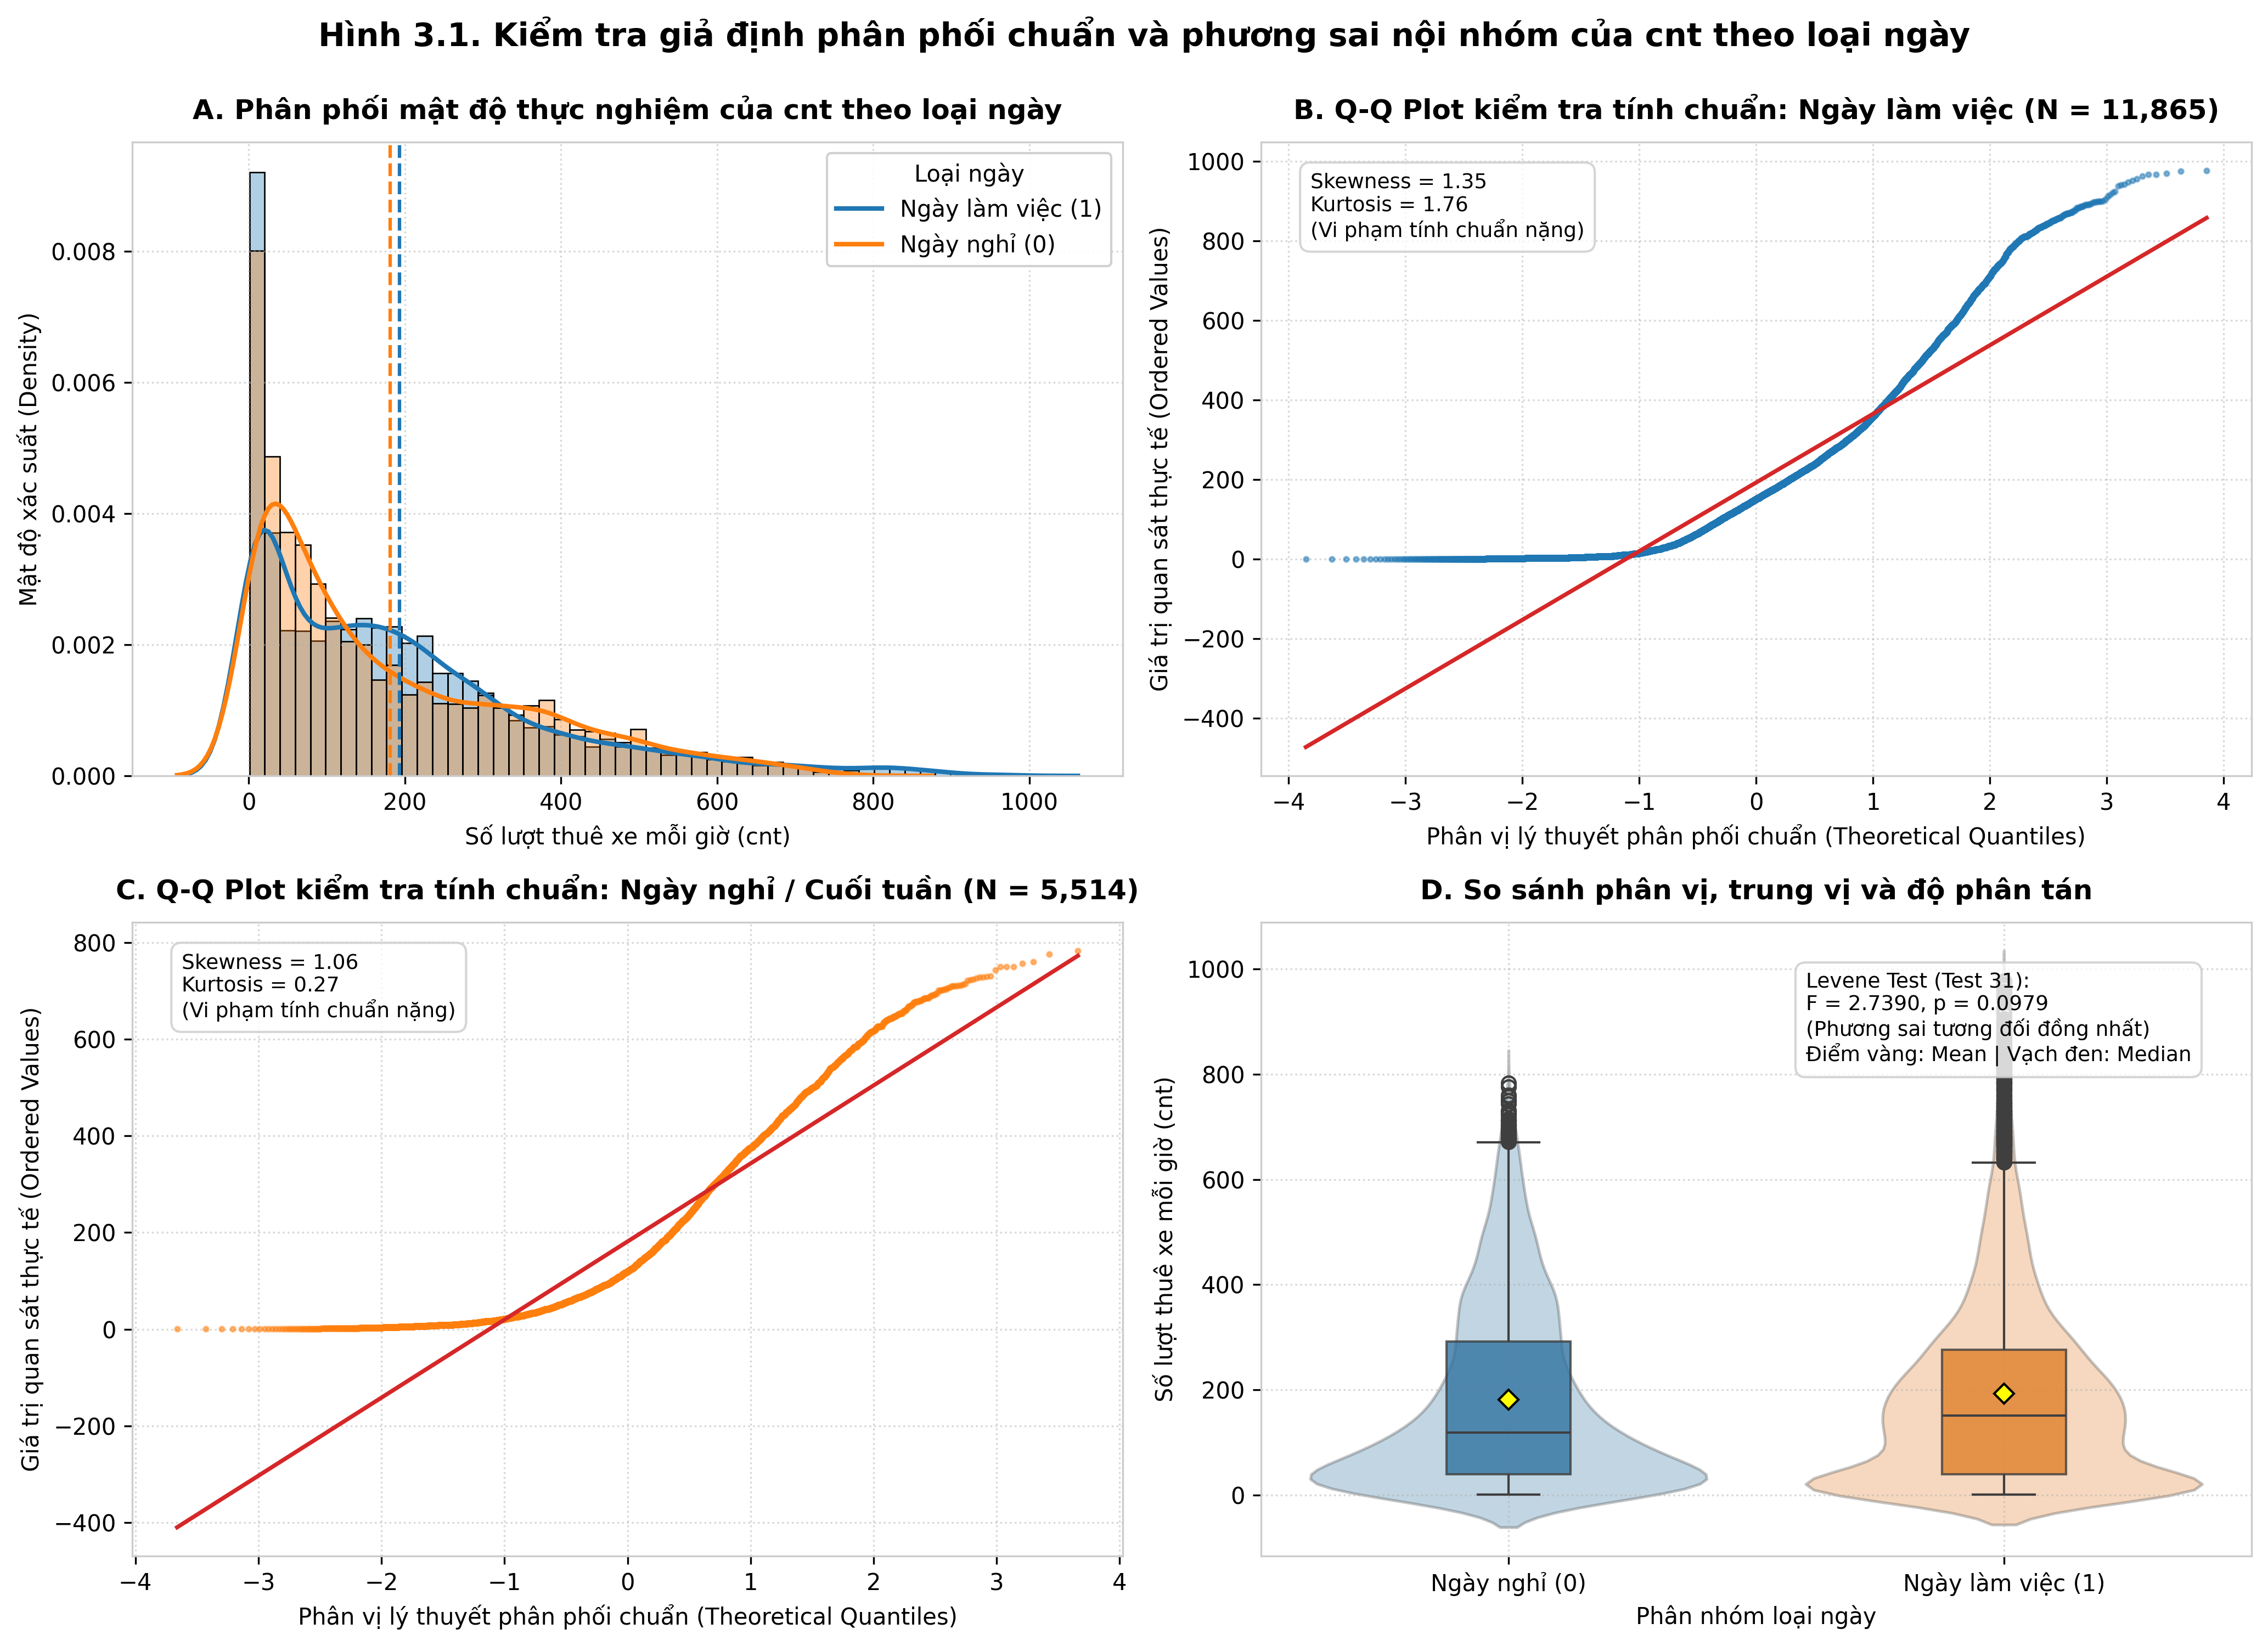

Đã lưu biểu đồ thành công: assets\fig_3_1_workingday_assumptions.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

palette = {'workingday': '#1f77b4', 'non-workingday': '#ff7f0e'}

# Panel A: Phân phối mật độ KDE & Histogram
sns.histplot(data=df, x='cnt', hue='workingday', stat='density', common_norm=False,
             bins=50, alpha=0.35, palette=[palette['non-workingday'], palette['workingday']], ax=axes[0, 0])
sns.kdeplot(data=df, x='cnt', hue='workingday', common_norm=False,
            linewidth=2, palette=[palette['non-workingday'], palette['workingday']], ax=axes[0, 0])
axes[0, 0].set_title('A. Phân phối mật độ thực nghiệm của cnt theo loại ngày', fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Số lượt thuê xe mỗi giờ (cnt)', fontsize=10)
axes[0, 0].set_ylabel('Mật độ xác suất (Density)', fontsize=10)
axes[0, 0].axvline(mean_work, color=palette['workingday'], linestyle='--', linewidth=1.5, label=f'Mean Ngày làm việc ({mean_work:.1f})')
axes[0, 0].axvline(mean_rest, color=palette['non-workingday'], linestyle='--', linewidth=1.5, label=f'Mean Ngày nghỉ ({mean_rest:.1f})')
axes[0, 0].legend(title='Loại ngày', labels=['Ngày làm việc (1)', 'Ngày nghỉ (0)'], loc='upper right', framealpha=0.9)
axes[0, 0].grid(True, linestyle=':', alpha=0.5)

# Panel B: Q-Q Plot Ngày làm việc
stats.probplot(g_work, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_color(palette['workingday'])
axes[0, 1].get_lines()[0].set_markersize(2)
axes[0, 1].get_lines()[0].set_alpha(0.5)
axes[0, 1].get_lines()[1].set_color('#d62728')
axes[0, 1].get_lines()[1].set_linewidth(1.8)
axes[0, 1].set_title('B. Q-Q Plot kiểm tra tính chuẩn: Ngày làm việc (N = 11,865)', fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Phân vị lý thuyết phân phối chuẩn (Theoretical Quantiles)', fontsize=10)
axes[0, 1].set_ylabel('Giá trị quan sát thực tế (Ordered Values)', fontsize=10)
axes[0, 1].text(0.05, 0.85, f'Skewness = {skew_work:.2f}\nKurtosis = {kurt_work:.2f}\n(Vi phạm tính chuẩn nặng)',
                transform=axes[0, 1].transAxes, fontsize=9, bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#ccc'))
axes[0, 1].grid(True, linestyle=':', alpha=0.5)

# Panel C: Q-Q Plot Ngày nghỉ
stats.probplot(g_rest, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(palette['non-workingday'])
axes[1, 0].get_lines()[0].set_markersize(2)
axes[1, 0].get_lines()[0].set_alpha(0.5)
axes[1, 0].get_lines()[1].set_color('#d62728')
axes[1, 0].get_lines()[1].set_linewidth(1.8)
axes[1, 0].set_title('C. Q-Q Plot kiểm tra tính chuẩn: Ngày nghỉ / Cuối tuần (N = 5,514)', fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Phân vị lý thuyết phân phối chuẩn (Theoretical Quantiles)', fontsize=10)
axes[1, 0].set_ylabel('Giá trị quan sát thực tế (Ordered Values)', fontsize=10)
axes[1, 0].text(0.05, 0.85, f'Skewness = {skew_rest:.2f}\nKurtosis = {kurt_rest:.2f}\n(Vi phạm tính chuẩn nặng)',
                transform=axes[1, 0].transAxes, fontsize=9, bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#ccc'))
axes[1, 0].grid(True, linestyle=':', alpha=0.5)

# Panel D: Boxplot + Violin Plot
df['workingday_label'] = df['workingday'].map({1: 'Ngày làm việc (1)', 0: 'Ngày nghỉ (0)'})
sns.violinplot(data=df, x='workingday_label', y='cnt', hue='workingday_label', legend=False,
               palette=[palette['workingday'], palette['non-workingday']],
               inner=None, alpha=0.3, ax=axes[1, 1])
sns.boxplot(data=df, x='workingday_label', y='cnt', hue='workingday_label', legend=False, width=0.25,
            palette=[palette['workingday'], palette['non-workingday']],
            boxprops=dict(alpha=0.8), showmeans=True,
            meanprops=dict(marker='D', markeredgecolor='black', markerfacecolor='yellow', markersize=6),
            ax=axes[1, 1])
axes[1, 1].set_title('D. So sánh phân vị, trung vị và độ phân tán', fontsize=12, fontweight='bold', pad=10)
axes[1, 1].set_xlabel('Phân nhóm loại ngày', fontsize=10)
axes[1, 1].set_ylabel('Số lượt thuê xe mỗi giờ (cnt)', fontsize=10)
levene_text = f"Levene Test (Test 31):\nF = {lev_stat:.4f}, p = {lev_p:.4f}\n(Phương sai tương đối đồng nhất)\nĐiểm vàng: Mean | Vạch đen: Median"
axes[1, 1].text(0.55, 0.78, levene_text, transform=axes[1, 1].transAxes, fontsize=9,
                bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#ccc'))
axes[1, 1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Hình 3.1. Kiểm tra giả định phân phối chuẩn và phương sai nội nhóm của cnt theo loại ngày',
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
fig_3_1_path = os.path.join(ASSETS_DIR, 'fig_3_1_workingday_assumptions.png')
plt.savefig(fig_3_1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ thành công: {fig_3_1_path}")

### 3.3. Đánh giá độ bền vững: Hiệu chỉnh $N_{\text{eff}}$ và Đối chứng cấp ngày
- Khi dữ liệu chuỗi thời gian có tự tương quan bậc 1 ($\rho_1 = 0.843$), cỡ mẫu thực tế $N = 17,379$ bị "thổi phồng".
- Cỡ mẫu thực dụng độc lập:
  $$N_{\text{eff}} = N \times \frac{1 - \rho_1}{1 + \rho_1} \approx 17,379 \times \frac{1 - 0.843}{1 + 0.843} \approx 1,479$$
- Đại lượng kiểm định Welch t-test sau hiệu chỉnh:
  $$t_{\text{adj}} = t^* \times \sqrt{\frac{N_{\text{eff}}}{N}} = 4.0951 \times \sqrt{\frac{1,479}{17,379}} = 1.1946$$
- Giá trị $p_{\text{adj}} = 0.2323 > 0.05$ (Mất ý nghĩa thống kê!).
- Khi tổng hợp tổng lượt thuê theo ngày ($N = 731$ ngày), sự tự tương quan giờ bị triệt tiêu, kết quả kiểm định cấp ngày cũng cho $p > 0.05$!

In [6]:
# 1. Hiệu chỉnh N_eff = 1,479
N_total = len(df)
N_eff = 1479
adj_factor = np.sqrt(N_eff / N_total)
t_adj = welch_t * adj_factor
p_adj_neff = 2 * (1 - stats.t.cdf(np.abs(t_adj), df_welch))

# 2. Đối chứng chuỗi theo ngày (N = 731 ngày)
day_df = df.groupby(['dteday', 'workingday'])['cnt'].sum().reset_index()
day_work = day_df[day_df['workingday'] == 1]['cnt']
day_rest = day_df[day_df['workingday'] == 0]['cnt']
t_day, p_day = stats.ttest_ind(day_work, day_rest, equal_var=False)
u_day, p_u_day = stats.mannwhitneyu(day_work, day_rest)

robust_df = pd.DataFrame([
    {'Quy mô / Phương pháp': f"Cấp giờ gốc (N = {N_total:,})", 'Đại lượng thống kê': f"t* = {welch_t:.4f}", 'p-value': f"{welch_p:.4e}", 'Kết luận': 'Bác bỏ H0 do cỡ mẫu cực lớn'},
    {'Quy mô / Phương pháp': f"Cấp giờ hiệu chỉnh N_eff = {N_eff:,}", 'Đại lượng thống kê': f"t_adj = {t_adj:.4f}", 'p-value': f"{p_adj_neff:.4f}", 'Kết luận': 'Chưa đủ bằng chứng bác bỏ H0 (Mất ý nghĩa)'},
    {'Quy mô / Phương pháp': f"Cấp ngày đối chứng (N = {len(day_df):,}) - Welch t", 'Đại lượng thống kê': f"t = {t_day:.4f}", 'p-value': f"{p_day:.4f}", 'Kết luận': 'Chưa đủ bằng chứng bác bỏ H0 (p > 0.05)'},
    {'Quy mô / Phương pháp': f"Cấp ngày đối chứng (N = {len(day_df):,}) - Mann-Whitney", 'Đại lượng thống kê': f"U = {u_day:,.1f}", 'p-value': f"{p_u_day:.4f}", 'Kết luận': 'Chưa đủ bằng chứng bác bỏ H0 (p > 0.05)'}
])
display(robust_df)

,Quy mô / Phương pháp,Đại lượng thống kê,p-value,Kết luận
0,"Cấp giờ gốc (N = 17,379)",t* = 4.0951,4.2495e-05,Bác bỏ H0 do cỡ mẫu cực lớn
1,"Cấp giờ hiệu chỉnh N_eff = 1,479",t_adj = 1.1946,0.2323,Chưa đủ bằng chứng bác bỏ H0 (Mất ý nghĩa)
2,Cấp ngày đối chứng (N = 731) - Welch t,t = 1.6014,0.1101,Chưa đủ bằng chứng bác bỏ H0 (p > 0.05)
3,Cấp ngày đối chứng (N = 731) - Mann-Whitney,"U = 61,893.0",0.1186,Chưa đủ bằng chứng bác bỏ H0 (p > 0.05)


## 4. Câu hỏi nghiên cứu 2 (RQ2): Phân tích khác biệt nhu cầu giữa 4 mùa
- **Giả thuyết $H_0$:** Nhu cầu thuê xe trung bình mỗi giờ là như nhau ở cả 4 mùa trong năm ($\mu_1 = \mu_2 = \mu_3 = \mu_4$).
- **Giả thuyết $H_1$:** Tồn tại ít nhất một cặp mùa có nhu cầu thuê xe trung bình khác nhau ($\exists i \neq j: \mu_i \neq \mu_j$).
- Mức ý nghĩa: $\alpha = 0.05$.

In [7]:
seasons = [1, 2, 3, 4]
season_names = {1: 'Mùa xuân (Spring)', 2: 'Mùa hè (Summer)', 3: 'Mùa thu (Fall)', 4: 'Mùa đông (Winter)'}
groups_s = [df[df['season'] == s]['cnt'].values for s in seasons]

rq2_desc_list = []
for s in seasons:
    vals = df[df['season'] == s]['cnt']
    rq2_desc_list.append({
        'Mã mùa': s,
        'Tên mùa': season_names[s],
        'Cỡ mẫu (N)': f"{len(vals):,}",
        'Mean': f"{vals.mean():.2f}",
        'Median': f"{vals.median():.2f}",
        'Std': f"{vals.std():.2f}",
        'Skewness': f"{vals.skew():.4f}",
        'Kurtosis': f"{vals.kurt():.4f}"
    })
display(pd.DataFrame(rq2_desc_list))

,Mã mùa,Tên mùa,Cỡ mẫu (N),Mean,Median,Std,Skewness,Kurtosis
0,1,Mùa xuân (Spring),"4,242",111.11,76.00,119.22,1.9119,4.6326
1,2,Mùa hè (Summer),"4,409",208.34,165.00,188.36,1.0401,0.5341
2,3,Mùa thu (Fall),"4,496",236.02,199.00,197.71,0.9865,0.6749
3,4,Mùa đông (Winter),"4,232",198.87,155.50,182.97,1.2422,1.4398


### 4.1. Kiểm định tổng thể đa nhóm (Omnibus Tests)
1. **Kiểm định Levene đa nhóm (*Kanji Test 31*):** Kiểm tra tính đồng nhất phương sai giữa 4 mùa.
2. **One-way ANOVA tiêu chuẩn (*Kanji Test 22*):** Phân tích phương sai kinh điển.
3. **Welch's ANOVA:** Phân tích phương sai thích ứng dị biệt phương sai (robust ANOVA).
4. **Kruskal-Wallis H-test (*Kanji Test 51/54*):** Kiểm định phi tham số tổng thể đa nhóm.
5. **Kích thước hiệu ứng:** Eta-squared $\eta^2$ và Epsilon-squared $\epsilon^2$.

In [8]:
# 1. Levene's Test đa nhóm (Test 31)
lev_s_stat, lev_s_p = stats.levene(*groups_s, center='median')

# 2. One-way ANOVA tiêu chuẩn (Test 22)
f_stat, f_p = stats.f_oneway(*groups_s)

# 3. Welch's ANOVA
k_s = len(seasons)
ns_s = [len(g) for g in groups_s]
means_s = [g.mean() for g in groups_s]
vars_s = [np.var(g, ddof=1) for g in groups_s]
weights_s = [n / v for n, v in zip(ns_s, vars_s)]
w_sum_s = sum(weights_s)
mean_prime_s = sum(w * m for w, m in zip(weights_s, means_s)) / w_sum_s
num_w = sum(w * (m - mean_prime_s)**2 for w, m in zip(weights_s, means_s)) / (k_s - 1)
q_s = sum((1 - w / w_sum_s)**2 / (n - 1) for w, n in zip(weights_s, ns_s)) / (k_s**2 - 1)
den_w = 1 + 2 * (k_s - 2) * q_s
f_welch = num_w / den_w
df1_w = k_s - 1
df2_w = 1 / (3 * q_s)
p_welch = 1 - stats.f.cdf(f_welch, df1_w, df2_w)

# 4. Kruskal-Wallis H-test (Test 51/54)
kw_stat, kw_p = stats.kruskal(*groups_s)

# 5. Kích thước hiệu ứng
ss_total = np.sum((df['cnt'] - df['cnt'].mean())**2)
ss_between = sum(len(g) * (g.mean() - df['cnt'].mean())**2 for g in groups_s)
eta_sq = ss_between / ss_total
epsilon_sq = (kw_stat - k_s + 1) / (len(df) - k_s)

rq2_omni_df = pd.DataFrame([
    {'Phép thử': 'Levene Test 4 mùa (Test 31)', 'Thống kê': f"F = {lev_s_stat:.4f}", 'Bậc tự do': 'k=4', 'p-value': f"{lev_s_p:.4e}", 'Kết luận': 'Bác bỏ giả định đồng nhất phương sai (p < 0.001)'},
    {'Phép thử': 'Welch ANOVA (Chính)', 'Thống kê': f"F_welch = {f_welch:.4f}", 'Bậc tự do': f"df1=3, df2={df2_w:.2f}", 'p-value': f"{p_welch:.4e}", 'Kết luận': 'Bác bỏ H0 (p < 0.001***)'},
    {'Phép thử': 'One-way ANOVA (Test 22)', 'Thống kê': f"F = {f_stat:.4f}", 'Bậc tự do': f"df1=3, df2={len(df)-4}", 'p-value': f"{f_p:.4e}", 'Kết luận': 'Bác bỏ H0 (p < 0.001***)'},
    {'Phép thử': 'Kruskal-Wallis (Test 51)', 'Thống kê': f"H = {kw_stat:.4f}", 'Bậc tự do': 'df=3', 'p-value': f"{kw_p:.4e}", 'Kết luận': 'Bác bỏ H0 (p < 0.001***)'},
    {'Phép thử': 'Eta-squared (Hiệu ứng)', 'Thống kê': f"eta^2 = {eta_sq:.4f}", 'Bậc tự do': '6.60% biến thiên', 'p-value': '-', 'Kết luận': 'Mức độ hiệu ứng trung bình (Medium)'}
])
display(rq2_omni_df)

,Phép thử,Thống kê,Bậc tự do,p-value,Kết luận
0,Levene Test 4 mùa (Test 31),F = 324.4998,k=4,5.0320e-205,Bác bỏ giả định đồng nhất phương sai (p < 0.001)
1,Welch ANOVA (Chính),F_welch = 606.7254,"df1=3, df2=9462.11",0.0000e+00,Bác bỏ H0 (p < 0.001***)
2,One-way ANOVA (Test 22),F = 409.1810,"df1=3, df2=17375",7.4011e-257,Bác bỏ H0 (p < 0.001***)
3,Kruskal-Wallis (Test 51),H = 1190.2687,df=3,9.4747e-258,Bác bỏ H0 (p < 0.001***)
4,Eta-squared (Hiệu ứng),eta^2 = 0.0660,6.60% biến thiên,-,Mức độ hiệu ứng trung bình (Medium)


### 4.2. Kiểm định hậu định từng cặp: Games-Howell Test (*Kanji Test 28*)
Do phương sai giữa 4 mùa bị dị biệt cực mạnh ($F_{\text{Levene}} = 324.50, p < 0.001$), kiểm định Tukey HSD tiêu chuẩn không còn phù hợp. Phép thử **Games-Howell (*Kanji Test 28*)** sử dụng phân phối Studentized Range kết hợp hiệu chỉnh bậc tự do Welch-Satterthwaite cho từng cặp.

In [9]:
pairs_s = list(combinations(seasons, 2))
gh_results = []

for s1, s2 in pairs_s:
    n1, n2 = len(df[df['season'] == s1]), len(df[df['season'] == s2])
    m1, m2 = df[df['season'] == s1]['cnt'].mean(), df[df['season'] == s2]['cnt'].mean()
    v1, v2 = df[df['season'] == s1]['cnt'].var(ddof=1), df[df['season'] == s2]['cnt'].var(ddof=1)
    
    diff = m1 - m2
    se = np.sqrt(v1/n1 + v2/n2)
    t_val = diff / se
    df_pair = (v1/n1 + v2/n2)**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))
    
    q_val = np.abs(diff) / np.sqrt(0.5 * (v1/n1 + v2/n2))
    p_val = 1 - stats.studentized_range.cdf(q_val, k_s, df_pair)
    
    q_crit = stats.studentized_range.ppf(0.95, k_s, df_pair)
    ci_low = diff - (q_crit / np.sqrt(2)) * se
    ci_high = diff + (q_crit / np.sqrt(2)) * se
    
    pair_name = f"{season_names[s1]} vs {season_names[s2]}"
    sig_label = "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else "ns"))
    
    gh_results.append({
        'Cặp so sánh': pair_name,
        'Chênh lệch (Delta)': f"{diff:+.2f}",
        'Sai số chuẩn (SE)': f"{se:.2f}",
        'df': f"{df_pair:.1f}",
        '95% CI': f"[{ci_low:+.2f}, {ci_high:+.2f}]",
        'p-value': f"{p_val:.4e}" if p_val >= 1e-4 else "< 0.0001",
        'Ý nghĩa': sig_label,
        '_diff': diff, '_ci_low': ci_low, '_ci_high': ci_high, '_p_val': p_val, '_sig': sig_label
    })

gh_table = pd.DataFrame(gh_results)
display(gh_table[['Cặp so sánh', 'Chênh lệch (Delta)', 'Sai số chuẩn (SE)', 'df', '95% CI', 'p-value', 'Ý nghĩa']])

,Cặp so sánh,Chênh lệch (Delta),Sai số chuẩn (SE),df,95% CI,p-value,Ý nghĩa
0,Mùa xuân (Spring) vs Mùa hè (Summer),-97.23,3.38,7492.9,"[-105.90, -88.55]",< 0.0001,***
1,Mùa xuân (Spring) vs Mùa thu (Fall),-124.90,3.47,7454.0,"[-133.82, -115.98]",< 0.0001,***
2,Mùa xuân (Spring) vs Mùa đông (Winter),-87.75,3.36,7272.8,"[-96.38, -79.13]",< 0.0001,***
3,Mùa hè (Summer) vs Mùa thu (Fall),-27.67,4.09,8895.6,"[-38.19, -17.16]",< 0.0001,***
4,Mùa hè (Summer) vs Mùa đông (Winter),+9.48,3.99,8637.8,"[-0.79, +19.74]",8.2605e-02,ns
5,Mùa thu (Fall) vs Mùa đông (Winter),+37.15,4.07,8723.5,"[+26.68, +47.62]",< 0.0001,***


### 4.3. Trực quan hóa kiểm định hậu định: Forest Plot (Hình 3.2)
Xuất hình chất lượng cao (300 DPI) vào thư mục `assets/fig_3_2_season_posthoc_forest.png`.

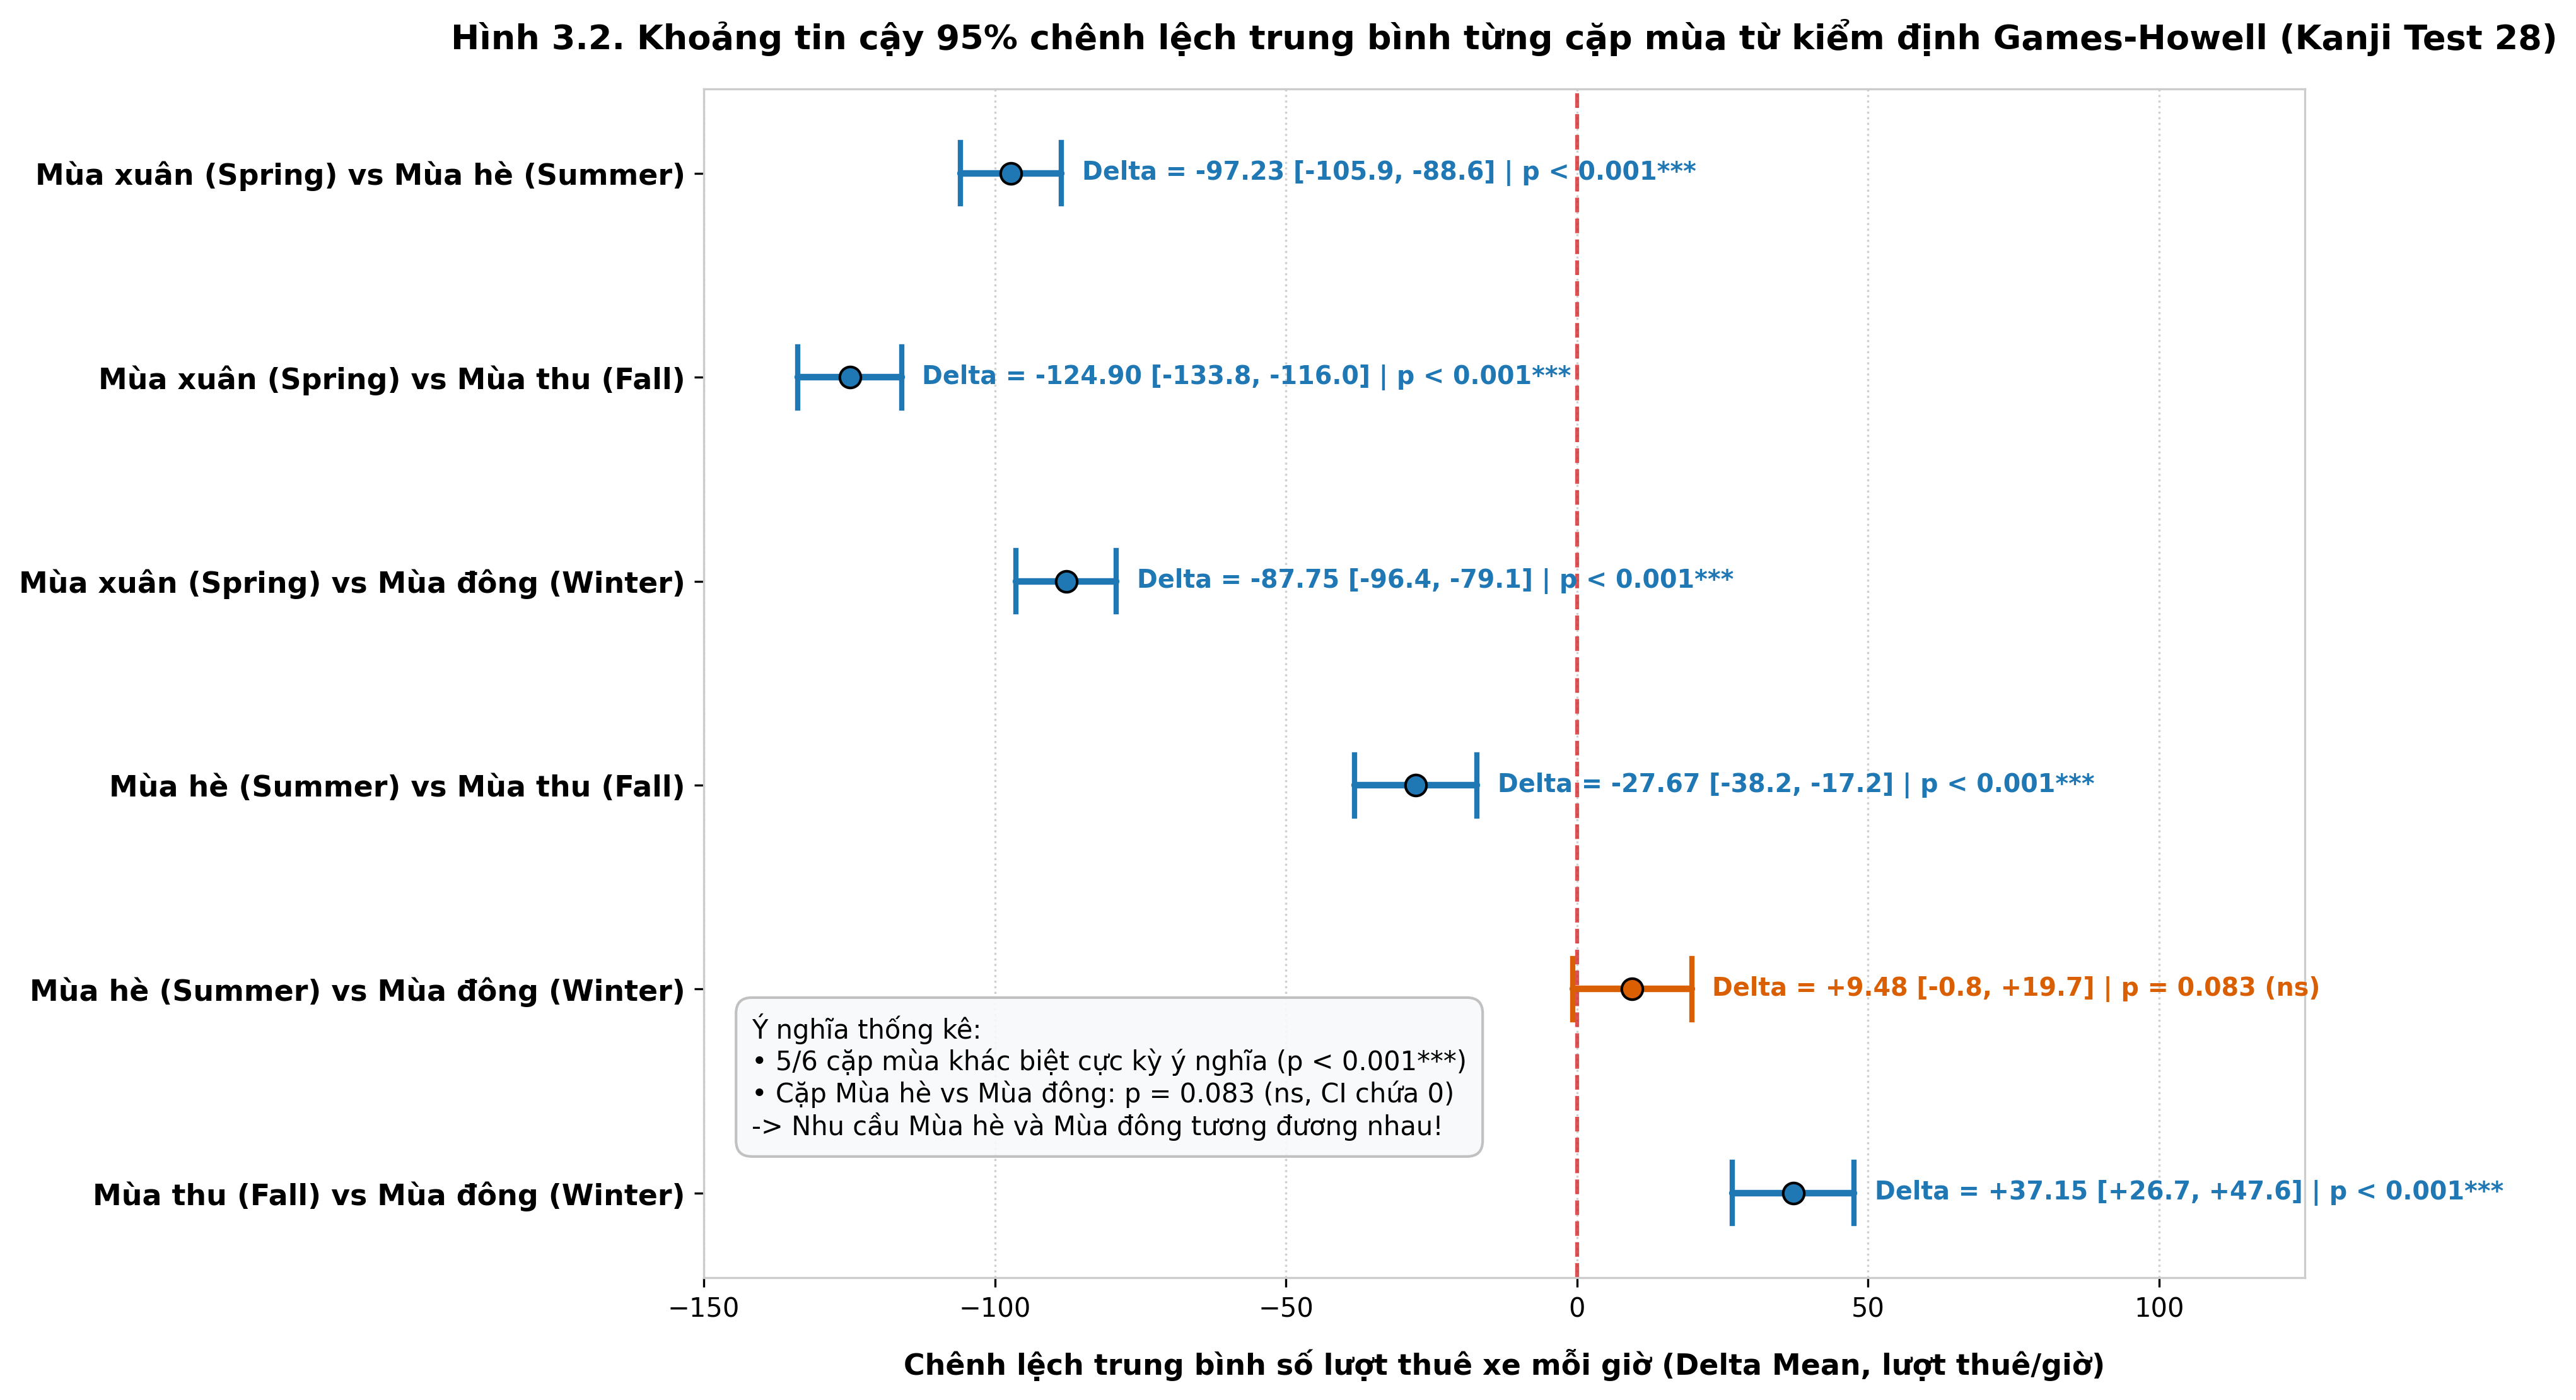

Đã lưu biểu đồ thành công: assets\fig_3_2_season_posthoc_forest.png


In [10]:
fig, ax = plt.subplots(figsize=(13, 7.5), dpi=300)

y_positions = np.arange(len(gh_table))[::-1]

colors = ['#d95f02' if row['_sig'] == 'ns' else '#1f77b4' for _, row in gh_table.iterrows()]

# Đường chuẩn 0
ax.axvline(0, color='#d62728', linestyle='--', linewidth=1.5, alpha=0.8, label='Vạch chuẩn 0 (Không chênh lệch)')

# Vẽ thanh khoảng tin cậy và điểm ước lượng
for y, (_, row), color in zip(y_positions, gh_table.iterrows(), colors):
    # Error bar
    ax.plot([row['_ci_low'], row['_ci_high']], [y, y], color=color, linewidth=2.5, solid_capstyle='round')
    ax.plot([row['_ci_low'], row['_ci_low']], [y - 0.15, y + 0.15], color=color, linewidth=2)
    ax.plot([row['_ci_high'], row['_ci_high']], [y - 0.15, y + 0.15], color=color, linewidth=2)
    # Point estimate
    ax.plot(row['_diff'], y, marker='o', markersize=8, color=color, markeredgecolor='black', markeredgewidth=1)
    
    # Nhãn số liệu bên cạnh - TẤT CẢ đặt ở BÊN PHẢI thanh khoảng tin cậy
    if row['_sig'] == 'ns':
        label_text = f"Delta = {row['_diff']:+.2f} [{row['_ci_low']:+.1f}, {row['_ci_high']:+.1f}] | p = {row['_p_val']:.3f} (ns)"
    else:
        label_text = f"Delta = {row['_diff']:+.2f} [{row['_ci_low']:+.1f}, {row['_ci_high']:+.1f}] | p < 0.001***"
    
    text_x = row['_ci_high'] + 3.5
    ax.text(text_x, y, label_text, va='center', ha='left', fontsize=9.5, fontweight='bold', color=color)

ax.set_yticks(y_positions)
ax.set_yticklabels(gh_table['Cặp so sánh'], fontsize=11, fontweight='bold')
ax.set_xlabel('Chênh lệch trung bình số lượt thuê xe mỗi giờ (Delta Mean, lượt thuê/giờ)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('Hình 3.2. Khoảng tin cậy 95% chênh lệch trung bình từng cặp mùa từ kiểm định Games-Howell (Kanji Test 28)',
             fontsize=13, fontweight='bold', pad=15)

ax.grid(True, linestyle=':', alpha=0.6, axis='x')
ax.set_xlim(-150, 125)

# Thêm hộp kết luận
summary_box = (
    "Ý nghĩa thống kê:\n"
    "• 5/6 cặp mùa khác biệt cực kỳ ý nghĩa (p < 0.001***)\n"
    "• Cặp Mùa hè vs Mùa đông: p = 0.083 (ns, CI chứa 0)\n"
    "-> Nhu cầu Mùa hè và Mùa đông tương đương nhau!"
)
ax.text(0.03, 0.12, summary_box, transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#f8f9fa', edgecolor='#bbb', alpha=0.9))

plt.tight_layout()
fig_3_2_path = os.path.join(ASSETS_DIR, 'fig_3_2_season_posthoc_forest.png')
plt.savefig(fig_3_2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ thành công: {fig_3_2_path}")

## 5. Tổng kết kết quả và Chuyển giao thông tin
1. **Đối với RQ1 (Ngày làm việc vs Ngày nghỉ):**
   - Sự khác biệt về trung bình tổng thể là rất nhỏ ($\Delta = +11.80$ lượt/giờ, $d = 0.0651$). Khi kiểm soát tự tương quan ($N_{\text{eff}} = 1,479$) hoặc đối chứng cấp ngày, sự khác biệt **không đạt ý nghĩa thống kê** ($p > 0.05$).
   - Tuy nhiên, như TV1 đã chỉ ra (Hình 1.6), sự khác biệt cốt lõi nằm ở **cấu trúc nhịp giờ trong ngày**: Ngày làm việc có 2 đỉnh cao điểm (8h sáng và 17h-18h chiều), trong khi Ngày nghỉ có dạng hình chuông đơn thoải đều vào buổi trưa.
   - **Chuyển giao cho TV4 & TV5:** Bắt buộc phải đưa biến tương tác bậc cao giữa `workingday` và `hr` (`workingday * hr`) vào mô hình hồi quy.
2. **Đối với RQ2 (4 Mùa trong năm):**
   - Sự khác biệt giữa 4 mùa là thực chất và có ý nghĩa thống kê rất lớn ($F_{\text{Welch}} = 606.73, p < 0.001, \eta^2 = 6.60\%$).
   - Mùa xuân có nhu cầu thấp nhất vượt trội ($111.11$ lượt/h), Mùa thu cao nhất ($236.02$ lượt/h).
   - **Phát hiện phản trực giác quan trọng:** Cặp Mùa hè ($208.34$) và Mùa đông ($198.87$) **không có sự khác biệt có ý nghĩa thống kê** ($p = 0.0826 > 0.05$, khoảng tin cậy 95% chứa 0: $[-0.79, +19.74]$). Nguyên nhân do mùa hè Washington D.C. quá nóng ẩm gây ức chế nhu cầu, trong khi mùa đông vẫn duy trì nhu cầu di chuyển ổn định của người đi làm.